# P3 Corrective RAG — Variant (Roll 67): Retrieval Evaluator with a KG-Lookup Fallback on CRAG
**Course:** Knowledge Graph and Information Retrieval Systems Lab (26CMPE742) · **Student:** Manish Raje, Roll 67, D17B

This notebook runs end to end on Colab (T4) or a local GPU. Steps:
1. Load and stratify-sample **200 questions** from the CRAG benchmark (Meta, KDD Cup 2024).
2. Parse the 5 web pages per question, chunk them, embed with **BGE-small-en-v1.5** and retrieve the top-k chunks.
3. Score retrieved chunks with a **retrieval evaluator** (BGE-reranker-base cross-encoder) → `correct / ambiguous / incorrect`.
4. Corrective action: *correct* → refined chunks; *incorrect* → **KG lookup (Wikidata)** instead of web search; *ambiguous* → both.
5. Generate answers with **Qwen2.5-1.5B-Instruct** (≤3B) for three methods: no retrieval, standard RAG, corrective RAG (3 seeds).
6. Evaluate accuracy / hallucination / EM / F1, fallback rate and accuracy **by question type**, retrieval metrics, cost.

In [1]:
# --- Setup (Colab: uncomment the pip line) ---
# !pip -q install sentence-transformers==5.1.2 transformers==4.57.1 accelerate rank_bm25 beautifulsoup4 lxml seaborn
import os, re, json, bz2, time, random, string, collections, math
import numpy as np, pandas as pd, torch, requests
import matplotlib.pyplot as plt, seaborn as sns
from bs4 import BeautifulSoup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = os.path.abspath(".")
DATA, OUT, FIG = [os.path.join(ROOT, d) for d in ("data", "results", "figures")]
for d in (DATA, OUT, FIG): os.makedirs(d, exist_ok=True)
EMBEDDER, RERANKER, LLM = "BAAI/bge-small-en-v1.5", "BAAI/bge-reranker-base", "Qwen/Qwen2.5-1.5B-Instruct"
GEN_SEEDS = [0, 1, 2]
RAG_SEEDS = [0]          # time budget on a throttled 4 GB laptop GPU: RAG methods run with 1 seed (std reported as n/a)
print("torch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 3050 Ti Laptop GPU


## 1. Dataset: CRAG (Task 1 & 2 dev v4), 200-question stratified subset
Two of the stratified CRAG subsets published at `Quivr/CRAG` (272 questions) form the pool; 200 are drawn with proportional stratification on `question_type` (seed 42).

In [2]:
def load_crag(path):
    """Subset files are concatenated pretty-printed JSON objects, so decode them one by one."""
    s, dec, p, rows = bz2.open(path, "rt", encoding="utf8").read(), json.JSONDecoder(), 0, []
    while True:
        while p < len(s) and s[p].isspace(): p += 1
        if p >= len(s): return rows
        o, p = dec.raw_decode(s, p); rows.append(o)

URL = "https://huggingface.co/datasets/Quivr/CRAG/resolve/main/subset/crag_task_1_and_2/crag_task_1_and_2_dev_v4_subset_{}.jsonl.bz2"
pool = []
for i in (1, 2):
    f = os.path.join(DATA, f"s{i}.jsonl.bz2")
    if not os.path.exists(f):
        open(f, "wb").write(requests.get(URL.format(i), timeout=300).content)
    pool += load_crag(f)

rng = random.Random(SEED)
by_type = collections.defaultdict(list)
for r in pool: by_type[r["question_type"]].append(r)
quota = {t: round(200 * len(v) / len(pool)) for t, v in by_type.items()}
while sum(quota.values()) != 200:                       # fix rounding drift on the largest stratum
    big = max(quota, key=quota.get); quota[big] += 1 if sum(quota.values()) < 200 else -1
sample = [r for t in sorted(by_type) for r in rng.sample(by_type[t], quota[t])]
rng.shuffle(sample)
print("pool:", len(pool), "| sample:", len(sample))
summary = pd.DataFrame({"pool": {t: len(v) for t, v in by_type.items()}, "sample": quota})
summary.loc["TOTAL"] = summary.sum(); print(summary)
print(pd.Series(collections.Counter(r["domain"] for r in sample), name="domain"))

pool: 272 | sample: 200
                    pool  sample
post-processing       12       9
simple_w_condition    40      29
set                   25      18
simple                77      56
aggregation           32      24
comparison            31      23
false_premise         31      23
multi-hop             24      18
TOTAL                272     200
movie      43
music      26
finance    49
open       36
sports     46
Name: domain, dtype: int64


In [3]:
ex = sample[0]
print({k: v for k, v in ex.items() if k != "search_results"})
print("pages:", [p["page_name"][:60] for p in ex["search_results"]])

{'interaction_id': '8d194198-f9a6-4988-a509-d3c138af56a6', 'query_time': '03/19/2024, 23:47:33 PT', 'domain': 'movie', 'question_type': 'simple', 'static_or_dynamic': 'static', 'query': 'who won the oscar best actor in 2019?', 'answer': 'rami malek', 'split': 1}
pages: ["LIST: Every actor that has won 'Best Actor' at the Academy A", 'Oscar Best Actor Gallery: Every Winner in Academy Award Hist', 'Academy Award for Best Actor - Wikipedia', "LIST: Every actor that has won 'Best Actor' at the Academy A", 'Oscar Best Actor Gallery: Every Winner in Academy Award Hist']


## 2. Page parsing, chunking and dense retrieval (BGE-small)
HTML → visible text → 200-word chunks with 40-word overlap. Retrieval is per question over its own 5 pages (CRAG Task 1 setting).

In [4]:
CHUNK, OVERLAP, MAX_WORDS_PAGE = 200, 40, 6000

def html_text(html):
    soup = BeautifulSoup(html, "lxml")
    for t in soup(["script", "style", "noscript", "header", "footer", "nav"]): t.decompose()
    return re.sub(r"\s+", " ", soup.get_text(" ")).strip()

def chunk_words(text):
    w = text.split()[:MAX_WORDS_PAGE]
    return [" ".join(w[i:i + CHUNK]) for i in range(0, max(len(w) - OVERLAP, 1), CHUNK - OVERLAP)]

t0 = time.time()
for r in sample:
    r["chunks"] = []
    for p in r["search_results"]:
        body = html_text(p["page_result"]) if p["page_result"] else ""
        r["chunks"] += [f"{p['page_name']}: {c}" for c in chunk_words(p["page_snippet"] + " " + body) if c]
    del r["search_results"]                              # free ~400 MB of raw HTML
parse_time = time.time() - t0
n_chunks = [len(r["chunks"]) for r in sample]
print(f"parsed in {parse_time:.1f}s | chunks total={sum(n_chunks)} mean/q={np.mean(n_chunks):.1f}")

C:\Users\Manish Raje\AppData\Local\Temp\ipykernel_5292\3434445447.py:4: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(html, "lxml")


parsed in 62.4s | chunks total=13036 mean/q=65.2


In [5]:
from sentence_transformers import SentenceTransformer, CrossEncoder
emb = SentenceTransformer(EMBEDDER, device=DEVICE)
QPFX = "Represent this sentence for searching relevant passages: "
K = 10
t0 = time.time()
for r in sample:
    cv = emb.encode(r["chunks"], batch_size=64, normalize_embeddings=True)
    qv = emb.encode(QPFX + r["query"], normalize_embeddings=True)
    order = np.argsort(-(cv @ qv))[:K]
    r["ret"] = [r["chunks"][i] for i in order]
embed_time = time.time() - t0
print(f"embedding + retrieval: {embed_time:.1f}s")

D:\KGIRs\67_P3_Variant\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


embedding + retrieval: 121.0s


## 3. Ground-truth retrieval quality and retrieval metrics
A chunk is **relevant** if it contains the normalised gold answer (or an alternative answer); for answers longer than 3 tokens, ≥75 % of the answer tokens must appear. False-premise questions (gold = "invalid question") have no supporting chunk and are excluded from retrieval metrics.

In [6]:
def norm(s):
    s = s.lower().replace(",", "")
    s = "".join(ch for ch in s if ch not in set(string.punctuation) - {"."})
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def golds(r): return [r["answer"]] + list(r.get("alt_ans") or [])

def supports(chunk, r):
    c = norm(chunk); ctoks = set(c.split())
    for g in map(norm, golds(r)):
        toks = g.split()
        if not toks: continue
        if g in c or (len(toks) > 3 and sum(t in ctoks for t in toks) / len(toks) >= 0.75): return True
    return False

def is_invalid(r): return norm(r["answer"]) == "invalid question"

for r in sample:
    r["rel"] = [supports(c, r) for c in r["ret"]]
    r["in_pool"] = (not is_invalid(r)) and any(supports(c, r) for c in r["chunks"])

def ret_metrics(rels, n_rel_total):
    rec = lambda k: float(any(rels[:k]))
    mrr = next((1 / (i + 1) for i, x in enumerate(rels) if x), 0.0)
    dcg = sum(x / math.log2(i + 2) for i, x in enumerate(rels[:10]))
    idcg = sum(1 / math.log2(i + 2) for i in range(min(n_rel_total, 10)))
    return rec(5), rec(10), mrr, dcg / idcg if idcg else 0.0

answerable = [r for r in sample if not is_invalid(r)]
M = np.array([ret_metrics(r["rel"], sum(supports(c, r) for c in r["chunks"])) for r in answerable])
ret_table = pd.DataFrame([M.mean(0)], columns=["Recall@5", "Recall@10", "MRR", "NDCG@10"], index=["BGE-small dense"]).round(3)
print(f"answerable={len(answerable)} | answer present anywhere in the 5 pages: {np.mean([r['in_pool'] for r in answerable]):.3f}")
print(ret_table)

answerable=177 | answer present anywhere in the 5 pages: 0.565
                 Recall@5  Recall@10    MRR  NDCG@10
BGE-small dense     0.463      0.514  0.408    0.335


## 4. Retrieval evaluator (same as Primary): cross-encoder confidence → correct / ambiguous / incorrect
Each of the top-5 chunks is scored by BGE-reranker-base (sigmoid). Following CRAG (Yan et al., 2024): if any chunk ≥ **upper** → *correct*; if all < **lower** → *incorrect*; otherwise *ambiguous*. Knowledge refinement keeps chunks with score ≥ lower.

In [7]:
UPPER, LOWER, TOPN = 0.60, 0.15, 5
rer = CrossEncoder(RERANKER, device=DEVICE, max_length=512)
t0 = time.time()
for r in sample:
    r["ev_scores"] = rer.predict([(r["query"], c) for c in r["ret"][:TOPN]], activation_fn=torch.nn.Sigmoid()).tolist()
    m = max(r["ev_scores"])
    r["label"] = "correct" if m >= UPPER else "incorrect" if m < LOWER else "ambiguous"
    r["refined"] = [c for c, s in zip(r["ret"][:TOPN], r["ev_scores"]) if s >= LOWER]
eval_time = time.time() - t0
lab = pd.Series(collections.Counter(r["label"] for r in sample)).reindex(["correct", "ambiguous", "incorrect"])
fallback_rate = (lab["ambiguous"] + lab["incorrect"]) / len(sample)
del rer; torch.cuda.empty_cache()                         # free VRAM for the generator (4 GB GPU)
print(f"evaluator time {eval_time:.1f}s"); print(lab); print(f"KG fallback rate = {fallback_rate:.3f}")

evaluator time 25.9s
correct      165
ambiguous     18
incorrect     17
dtype: int64
KG fallback rate = 0.175


## 5. Generator (Qwen2.5-1.5B-Instruct) and token accounting

In [8]:
from transformers import AutoTokenizer, AutoModelForCausalLM
tok = AutoTokenizer.from_pretrained(LLM, padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()
TOKENS = collections.Counter()

def chat(prompts, max_new=48, seed=None, stage="gen", bs=4):
    outs = []
    for i in range(0, len(prompts), bs):
        msgs = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True) for p in prompts[i:i + bs]]
        enc = tok(msgs, return_tensors="pt", padding=True, truncation=True, max_length=1100).to(DEVICE)
        kw = dict(do_sample=True, temperature=0.7, top_p=0.9) if seed is not None else dict(do_sample=False)
        if seed is not None: torch.manual_seed(seed * 1000 + i)
        with torch.no_grad():
            g = llm.generate(**enc, max_new_tokens=max_new, pad_token_id=tok.eos_token_id, **kw)
        new = g[:, enc["input_ids"].shape[1]:]
        TOKENS[stage + "_in"] += int(enc["attention_mask"].sum()); TOKENS[stage + "_out"] += int((new != tok.eos_token_id).sum())
        outs += [o.strip() for o in tok.batch_decode(new, skip_special_tokens=True)]
    return outs

print(chat(["What is the capital of France? Answer in a few words."]))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


['Paris']


## 6. KG-lookup fallback (Wikidata)
For *incorrect* / *ambiguous* questions the original CRAG would call web search. This Variant replaces it with a **knowledge-graph lookup**:
LLM entity extraction → Wikidata `wbsearchentities` → entity claims (property, value) verbalised as triples → top-15 triples ranked by BGE similarity to the question. Responses are cached in `data/kg_cache.json` so reruns are deterministic and offline.

In [9]:
WD = "https://www.wikidata.org/w/api.php"
HDR = {"User-Agent": "KGIRs-CRAG-KG-fallback/1.0 (VESIT student micro-project; https://vesit.ves.ac.in) python-requests"}
CACHE_F = os.path.join(DATA, "kg_cache.json")
cache = json.load(open(CACHE_F)) if os.path.exists(CACHE_F) else {}

def wd(params):
    """Cached, throttled Wikidata API call; honours HTTP 429 Retry-After and never caches failures."""
    key = json.dumps(params, sort_keys=True)
    if key in cache: return cache[key]
    for a in range(6):
        time.sleep(0.5)                                   # stay well under Wikimedia rate limits
        try:
            resp = requests.get(WD, params={**params, "format": "json", "maxlag": 5}, headers=HDR, timeout=30)
            if resp.status_code == 429 or "error" in resp.text[:200] and "maxlag" in resp.text[:300]:
                time.sleep(float(resp.headers.get("Retry-After", 10 * (a + 1)))); continue
            cache[key] = resp.json(); return cache[key]
        except Exception:
            time.sleep(3 * (a + 1))
    return {}

def labels(ids):
    out = {}
    for i in range(0, len(ids), 50):
        ents = wd({"action": "wbgetentities", "ids": "|".join(ids[i:i + 50]), "props": "labels", "languages": "en"}).get("entities", {})
        out.update({k: v.get("labels", {}).get("en", {}).get("value", k) for k, v in ents.items()})
    return out

def value_str(dv):
    v, t = dv.get("value"), dv.get("type")
    if t == "wikibase-entityid": return v["id"]
    if t == "time": return v["time"].lstrip("+").split("T")[0]
    if t == "quantity": return v["amount"].lstrip("+") + ("" if v.get("unit", "1") == "1" else " " + v["unit"].split("/")[-1])
    if t == "monolingualtext": return v["text"]
    return str(v)

def entity_triples(name, max_claims=120):
    hits = wd({"action": "wbsearchentities", "search": name, "language": "en", "limit": 1}).get("search", [])
    if not hits: return []
    qid, ename = hits[0]["id"], hits[0].get("label", name)
    claims = wd({"action": "wbgetentities", "ids": qid, "props": "claims"}).get("entities", {}).get(qid, {}).get("claims", {})
    raw = []
    for pid, cl in claims.items():
        for c in cl[:3]:
            sn = c.get("mainsnak", {}); dv = sn.get("datavalue")
            if dv and sn.get("datatype") not in ("external-id", "commonsMedia", "url", "geo-shape", "tabular-data"):
                raw.append((pid, value_str(dv)))
    raw = raw[:max_claims]
    lab = labels(sorted({p for p, _ in raw} | {v for _, v in raw if re.fullmatch(r"Q\d+", v)}))
    return [f"({ename}, {lab.get(p, p)}, {lab.get(v, v)})" for p, v in raw]

ENT_PROMPT = "List the main named entities (people, companies, films, songs, places, teams) in this question, comma-separated, nothing else.\nQuestion: {}"
def kg_lookup(rs, topk=15):
    ents = chat([ENT_PROMPT.format(r["query"]) for r in rs], max_new=32, stage="kg_entity")
    for r, e in zip(rs, ents):
        names = [x.strip(" .\"'") for x in e.split(",") if x.strip(" .\"'")][:3]
        trip = [t for n in names for t in entity_triples(n)]
        r["kg_entities"], r["kg_found"] = names, bool(trip)
        if trip:
            sims = emb.encode(trip, normalize_embeddings=True) @ emb.encode(QPFX + r["query"], normalize_embeddings=True)
            r["kg_facts"] = [trip[i] for i in np.argsort(-sims)[:topk]]
        else:
            r["kg_facts"] = []
    json.dump(cache, open(CACHE_F, "w"))

t0 = time.time()
fb = [r for r in sample if r["label"] != "correct"]
kg_lookup(fb)
for r in sample:
    r.setdefault("kg_facts", []); r.setdefault("kg_found", None)
kg_time = time.time() - t0
print(f"KG lookups for {len(fb)} questions in {kg_time:.1f}s | entity found for {np.mean([r['kg_found'] for r in fb]):.3f}")
ex = next(r for r in fb if r["kg_facts"]); print(ex["query"], ex["kg_entities"], *ex["kg_facts"][:6], sep="\n")

KG lookups for 35 questions in 210.5s | entity found for 0.829
which etf had a higher number of shares traded on the day before yesterday, clsk or bksy?
['ETF', 'Clsk', 'Bksy']
(Commando Luchtstrijdkrachten, short name, CLSK)
(Commando Luchtstrijdkrachten, country, Netherlands)
(Commando Luchtstrijdkrachten, military branch, Royal Netherlands Air Force)
(Commando Luchtstrijdkrachten, instance of, command)
(Commando Luchtstrijdkrachten, replaced by, Commando Lucht- en Ruimtestrijdkrachten)
(Commando Luchtstrijdkrachten, has use, aerial warfare)


## 7. Answer generation: no retrieval / standard RAG / corrective RAG (KG fallback), 3 seeds

In [10]:
SYS = ("You are a careful question-answering assistant. The question was asked on {qt}. Answer in as few words as possible. "
       "If the question contains a false premise, answer exactly 'invalid question'. If you are not sure, answer exactly 'I don't know'.\n")

def p_none(r): return SYS.format(qt=r["query_time"]) + f"Question: {r['query']}\nAnswer:"
def p_rag(r, docs, facts=()):
    ctx = "".join(f"[Doc {i+1}] {d[:400]}\n" for i, d in enumerate(docs))
    kg = "".join(f"- {f}\n" for f in facts)
    return (SYS.format(qt=r["query_time"]) + (f"Web documents:\n{ctx}" if docs else "") +
            (f"Knowledge-graph facts (Wikidata):\n{kg}" if kg else "") + f"Question: {r['query']}\nAnswer:")

def p_crag(r):
    if r["label"] == "correct":   return p_rag(r, r["refined"])
    if r["label"] == "incorrect": return p_rag(r, [], r["kg_facts"]) if r["kg_facts"] else p_none(r)
    return p_rag(r, r["refined"], r["kg_facts"])

METHODS = {"No retrieval": p_none, "Standard RAG (top-5)": lambda r: p_rag(r, r["ret"][:5]), "Corrective RAG + KG fallback": p_crag}
preds, gen_time = {}, {}
for m, fn in METHODS.items():
    prompts = [fn(r) for r in sample]
    for s in (GEN_SEEDS if m == "No retrieval" else RAG_SEEDS):
        t0 = time.time(); preds[(m, s)] = chat(prompts, seed=s, stage=m); gen_time[(m, s)] = time.time() - t0
        print(f"{m:30s} seed {s}: {gen_time[(m, s)]:.1f}s")

No retrieval                   seed 0: 55.7s


No retrieval                   seed 1: 52.6s


No retrieval                   seed 2: 63.3s


Standard RAG (top-5)           seed 0: 588.9s


Corrective RAG + KG fallback   seed 0: 579.0s


## 8. Scoring
CRAG-style automatic scoring: **accurate** if the normalised gold (or alt) answer is contained in the prediction, or token-F1 ≥ 0.5 for multi-word answers; "invalid question" must be stated for false premises. **Missing** = "I don't know". **Hallucination** = everything else. **CRAG score** = accuracy − hallucination. EM and token F1 are also reported.

In [11]:
def f1(p, g):
    p, g = norm(p).split(), norm(g).split()
    common = sum((collections.Counter(p) & collections.Counter(g)).values())
    if not p or not g or not common: return 0.0
    pr, rc = common / len(p), common / len(g); return 2 * pr * rc / (pr + rc)

def judge(pred, r):
    pn = norm(pred)
    if "i dont know" in pn or "i do not know" in pn or not pn: return "missing"
    if is_invalid(r): return "accurate" if "invalid question" in pn else "hallucinated"
    if "invalid question" in pn: return "hallucinated"
    for g in golds(r):
        gn = norm(g)
        if gn and (gn in pn or (len(gn.split()) > 1 and f1(pred, g) >= 0.5)): return "accurate"
    return "hallucinated"

rows = []
for (m, s), ps in preds.items():
    for r, p in zip(sample, ps):
        j = judge(p, r)
        rows.append(dict(method=m, seed=s, id=r["interaction_id"], qtype=r["question_type"], domain=r["domain"], label=r["label"],
                         pred=p, gold=r["answer"], judge=j, acc=j == "accurate", miss=j == "missing", hall=j == "hallucinated",
                         em=max(norm(p) == norm(g) for g in golds(r)), f1=max(f1(p, g) for g in golds(r))))
res = pd.DataFrame(rows)
res.to_csv(os.path.join(OUT, "per_question_predictions.csv"), index=False)

per_seed = res.groupby(["method", "seed"])[["acc", "miss", "hall", "em", "f1"]].mean()
per_seed["crag_score"] = per_seed["acc"] - per_seed["hall"]
T1 = per_seed.groupby("method").agg(["mean", "std"]).reindex(list(METHODS))
fmt = lambda c: T1[c].apply(lambda x: f"{100*x['mean']:.1f} ± {100*x['std']:.1f}", axis=1)
T1_show = pd.DataFrame({c: fmt(c) for c in ["acc", "miss", "hall", "crag_score", "em", "f1"]})
T1_show.columns = ["Accuracy %", "Missing %", "Hallucination %", "CRAG score %", "EM %", "F1 %"]
T1_show.index = [i + ("  [BASELINE]" if i == "No retrieval" else "") for i in T1_show.index]
print(T1_show.to_string())

                              Accuracy %   Missing % Hallucination % CRAG score %       EM %        F1 %
No retrieval  [BASELINE]      17.3 ± 1.4  17.2 ± 0.3      65.5 ± 1.3  -48.2 ± 2.8  8.8 ± 0.6  15.1 ± 0.2
Standard RAG (top-5)          17.0 ± nan  11.5 ± nan      71.5 ± nan  -54.5 ± nan  7.0 ± nan  14.8 ± nan
Corrective RAG + KG fallback  18.0 ± nan  13.5 ± nan      68.5 ± nan  -50.5 ± nan  7.5 ± nan  16.5 ± nan


In [12]:
lab_counts = pd.DataFrame({"count": lab, "share %": (100 * lab / len(sample)).round(1)})
lab_counts.loc["KG fallback (ambiguous+incorrect)"] = [lab["ambiguous"] + lab["incorrect"], round(100 * fallback_rate, 1)]
lab_counts.loc["KG entity found (of fallbacks)"] = [sum(bool(r["kg_found"]) for r in fb), round(100 * np.mean([bool(r["kg_found"]) for r in fb]), 1)]
print(lab_counts)

                                   count  share %
correct                              165     82.5
ambiguous                             18      9.0
incorrect                             17      8.5
KG fallback (ambiguous+incorrect)     35     17.5
KG entity found (of fallbacks)        29     82.9


## 9. Variant analysis: fallback rate and accuracy by question type

In [13]:
qt = res.groupby(["qtype", "method", "seed"])["acc"].mean().groupby(["qtype", "method"]).agg(["mean", "std"]).unstack("method")
fb_by = pd.DataFrame([dict(qtype=r["question_type"], fallback=r["label"] != "correct", incorrect=r["label"] == "incorrect") for r in sample]).groupby("qtype")
T3 = pd.DataFrame({"n": fb_by.size(), "fallback rate %": (100 * fb_by["fallback"].mean()).round(1), "incorrect %": (100 * fb_by["incorrect"].mean()).round(1)})
for m in METHODS:
    T3[m + " acc %"] = [f"{100*a:.1f} ± {100*b:.1f}" for a, b in zip(qt[("mean", m)], qt[("std", m)])]
T3 = T3.sort_values("fallback rate %", ascending=False)
print(T3.to_string())

# accuracy of corrective RAG split by evaluator branch
br = res[res.method.isin(["Standard RAG (top-5)", "Corrective RAG + KG fallback"])].groupby(["label", "method", "seed"])["acc"].mean().groupby(["label", "method"]).mean().unstack()
print((100 * br).round(1))

                     n  fallback rate %  incorrect % No retrieval acc % Standard RAG (top-5) acc % Corrective RAG + KG fallback acc %
qtype                                                                                                                                
comparison          23             26.1         21.7         29.0 ± 9.1                 21.7 ± nan                         26.1 ± nan
simple              56             23.2         14.3          7.7 ± 2.7                 19.6 ± nan                         19.6 ± nan
false_premise       23             21.7          8.7         66.7 ± 5.0                 21.7 ± nan                         26.1 ± nan
simple_w_condition  29             20.7          0.0          6.9 ± 3.4                 17.2 ± nan                         17.2 ± nan
aggregation         24             12.5          4.2          4.2 ± 0.0                  4.2 ± nan                          4.2 ± nan
multi-hop           18             11.1          5.6          

## 10. Figures

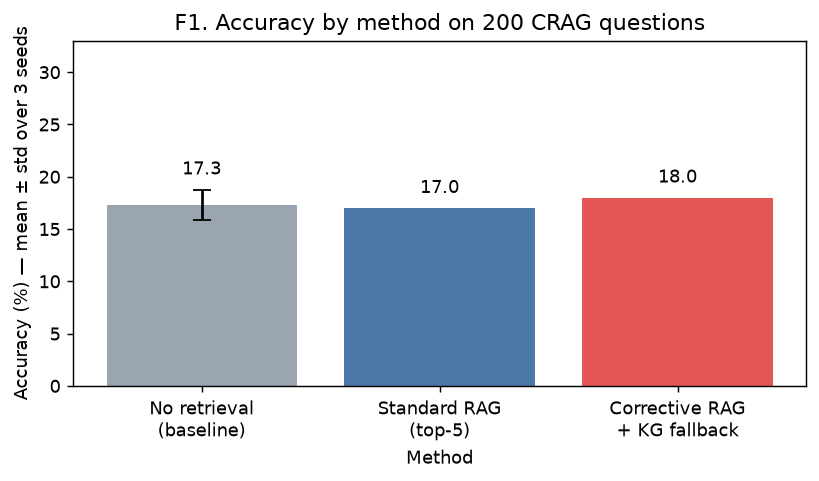

In [14]:
plt.rcParams.update({"figure.dpi": 130, "font.size": 10})
order = list(METHODS); mu = [T1.loc[m, ("acc", "mean")] * 100 for m in order]; sd = [T1.loc[m, ("acc", "std")] * 100 for m in order]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
b = ax.bar(["No retrieval\n(baseline)", "Standard RAG\n(top-5)", "Corrective RAG\n+ KG fallback"], mu, yerr=sd, capsize=5, color=["#9aa5b1", "#4c78a8", "#e45756"])
ax.bar_label(b, labels=[f"{m:.1f}" for m in mu], padding=6)
ax.set_ylabel("Accuracy (%) — mean ± std over 3 seeds"); ax.set_xlabel("Method"); ax.set_ylim(0, max(mu) + 15)
ax.set_title("F1. Accuracy by method on 200 CRAG questions"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "F1_accuracy_by_method.png")); plt.show()

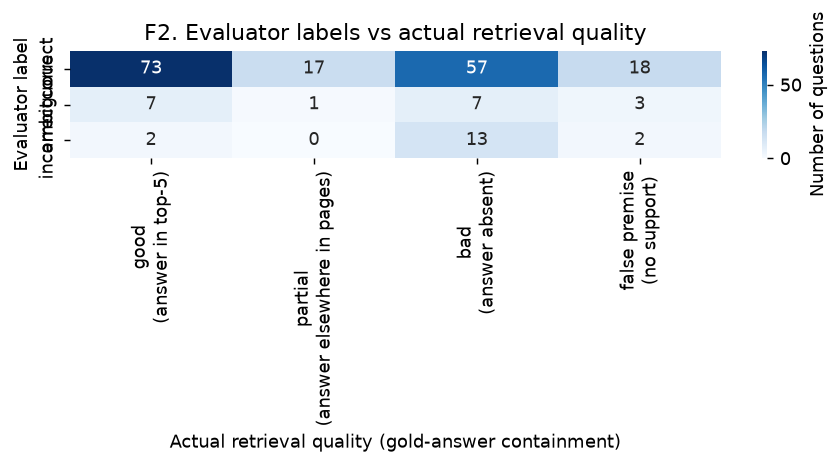

'correct' label precision for good retrieval = 0.442 | recall = 0.890


In [15]:
from sklearn.metrics import confusion_matrix
def actual(r):
    if is_invalid(r): return "false premise\n(no support)"
    if any(r["rel"][:5]): return "good\n(answer in top-5)"
    return "partial\n(answer elsewhere in pages)" if r["in_pool"] else "bad\n(answer absent)"
acts = ["good\n(answer in top-5)", "partial\n(answer elsewhere in pages)", "bad\n(answer absent)", "false premise\n(no support)"]
labs = ["correct", "ambiguous", "incorrect"]
cm = pd.crosstab(pd.Categorical([r["label"] for r in sample], labs), pd.Categorical([actual(r) for r in sample], acts), dropna=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "Number of questions"}, ax=ax)
ax.set_ylabel("Evaluator label"); ax.set_xlabel("Actual retrieval quality (gold-answer containment)")
ax.set_title("F2. Evaluator labels vs actual retrieval quality"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "F2_confusion_matrix.png")); plt.show()
good = np.array([actual(r).startswith("good") for r in sample]); okl = np.array([r["label"] == "correct" for r in sample])
print(f"'correct' label precision for good retrieval = {good[okl].mean():.3f} | recall = {okl[good].mean():.3f}")

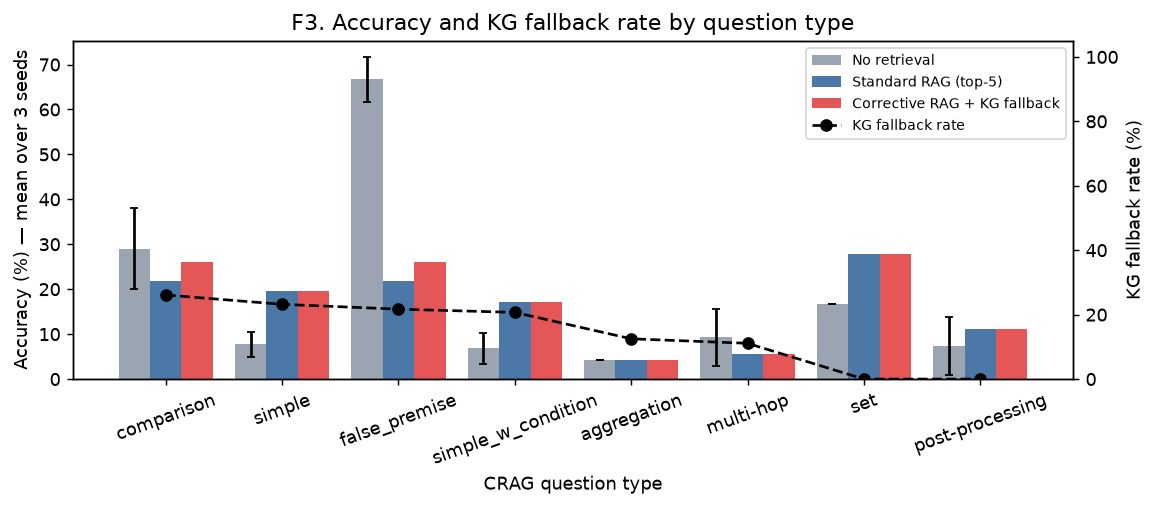

In [16]:
types = T3.index.tolist()
fig, ax1 = plt.subplots(figsize=(9, 4))
w = 0.27
for i, (m, c) in enumerate(zip(order, ["#9aa5b1", "#4c78a8", "#e45756"])):
    ax1.bar(np.arange(len(types)) + (i - 1) * w, [qt.loc[t, ("mean", m)] * 100 for t in types], w, yerr=[qt.loc[t, ("std", m)] * 100 for t in types], capsize=2, label=m, color=c)
ax1.set_xticks(range(len(types))); ax1.set_xticklabels(types, rotation=20); ax1.set_ylabel("Accuracy (%) — mean over 3 seeds"); ax1.set_xlabel("CRAG question type")
ax2 = ax1.twinx(); ax2.plot(range(len(types)), T3["fallback rate %"], "k--o", label="KG fallback rate"); ax2.set_ylabel("KG fallback rate (%)"); ax2.set_ylim(0, 105)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
ax1.set_title("F3. Accuracy and KG fallback rate by question type"); fig.tight_layout(); fig.savefig(os.path.join(FIG, "F3_by_question_type.png")); plt.show()

## 11. Threshold sensitivity of the evaluator (no re-generation; label shares only)

In [17]:
mx = np.array([max(r["ev_scores"]) for r in sample])
sens = []
for up in (0.4, 0.5, 0.6, 0.7, 0.8):
    for lo in (0.05, 0.15, 0.25):
        sens.append(dict(upper=up, lower=lo, correct=int((mx >= up).sum()), ambiguous=int(((mx < up) & (mx >= lo)).sum()), incorrect=int((mx < lo).sum()),
                         fallback_rate=round(float((mx < up).mean()), 3), correct_precision=round(float(good[mx >= up].mean()) if (mx >= up).any() else float("nan"), 3)))
T4 = pd.DataFrame(sens); print(T4.to_string(index=False))

 upper  lower  correct  ambiguous  incorrect  fallback_rate  correct_precision
   0.4   0.05      177         11         12          0.115              0.441
   0.4   0.15      177          6         17          0.115              0.441
   0.4   0.25      177          2         21          0.115              0.441
   0.5   0.05      171         17         12          0.145              0.444
   0.5   0.15      171         12         17          0.145              0.444
   0.5   0.25      171          8         21          0.145              0.444
   0.6   0.05      165         23         12          0.175              0.442
   0.6   0.15      165         18         17          0.175              0.442
   0.6   0.25      165         14         21          0.175              0.442
   0.7   0.05      156         32         12          0.220              0.449
   0.7   0.15      156         27         17          0.220              0.449
   0.7   0.25      156         23         21        

## 12. Cost: time and tokens

In [18]:
cost = pd.DataFrame([
    ("HTML parsing + chunking", parse_time, 0, 0),
    ("BGE-small embedding + retrieval", embed_time, 0, 0),
    ("Evaluator (BGE-reranker-base)", eval_time, 0, 0),
    ("KG lookup (entity extraction + Wikidata)", kg_time, TOKENS["kg_entity_in"], TOKENS["kg_entity_out"]),
] + [(f"Generation: {m}", sum(v for (mm, s), v in gen_time.items() if mm == m), TOKENS[m + "_in"], TOKENS[m + "_out"]) for m in METHODS],
    columns=["stage", "time_s", "prompt_tokens", "generated_tokens"])
cost["time_s"] = cost["time_s"].round(1)
cost["per_question_tokens"] = ((cost.prompt_tokens + cost.generated_tokens) / (len(sample) * np.where(cost.stage == "Generation: No retrieval", 3, 1))).round(0)
print(cost.to_string(index=False))

                                   stage  time_s  prompt_tokens  generated_tokens  per_question_tokens
                 HTML parsing + chunking    62.4              0                 0                  0.0
         BGE-small embedding + retrieval   121.0              0                 0                  0.0
           Evaluator (BGE-reranker-base)    25.9              0                 0                  0.0
KG lookup (entity extraction + Wikidata)   210.5           2699               209                 15.0
                Generation: No retrieval   171.6          74862              4881                133.0
        Generation: Standard RAG (top-5)   588.9         138362              2202                703.0
Generation: Corrective RAG + KG fallback   579.0         121401              2156                618.0


## 13. Save results and failure cases

In [19]:
T1_show.to_csv(os.path.join(OUT, "T1_accuracy_by_method.csv")); per_seed.to_csv(os.path.join(OUT, "metrics_per_seed.csv"))
lab_counts.to_csv(os.path.join(OUT, "T2_evaluator_labels.csv")); T3.to_csv(os.path.join(OUT, "T3_by_question_type.csv"))
T4.to_csv(os.path.join(OUT, "T4_threshold_sensitivity.csv"), index=False); cost.to_csv(os.path.join(OUT, "T5_cost.csv"), index=False)
ret_table.to_csv(os.path.join(OUT, "retrieval_metrics.csv")); cm.to_csv(os.path.join(OUT, "F2_confusion_counts.csv"))
long = per_seed.reset_index().melt(id_vars=["method", "seed"], var_name="metric")
long = pd.concat([long, ret_table.reset_index().melt(id_vars="index", var_name="metric").rename(columns={"index": "method"}).assign(seed="n/a (deterministic)")])
long.to_csv(os.path.join(OUT, "all_metrics.csv"), index=False)
json.dump([{k: r[k] for k in ("interaction_id", "query", "answer", "question_type", "label", "ev_scores", "kg_entities", "kg_facts") if k in r} for r in sample],
          open(os.path.join(OUT, "evaluator_and_kg_trace.json"), "w"), indent=1)

s0 = res[res.seed == 0].pivot(index="id", columns="method", values=["acc", "pred"])
meta = {r["interaction_id"]: r for r in sample}
fails = [i for i in s0.index if s0.loc[i, ("acc", "Standard RAG (top-5)")] and not s0.loc[i, ("acc", "Corrective RAG + KG fallback")]][:3]
fails += [i for i in s0.index if not s0.loc[i, ("acc", "Corrective RAG + KG fallback")] and meta[i]["label"] == "correct"][:2]
for i in fails:
    r = meta[i]
    print(f"\n[{r['question_type']}] {r['query']}\n gold: {r['answer']} | evaluator: {r['label']} (max={max(r['ev_scores']):.2f}) | KG entities: {r.get('kg_entities')}")
    print(" std RAG :", s0.loc[i, ("pred", "Standard RAG (top-5)")]); print(" CRAG+KG :", s0.loc[i, ("pred", "Corrective RAG + KG fallback")])
    if r["kg_facts"]: print(" top KG fact:", r["kg_facts"][0])
print("\nDone.")


[false_premise] what is the name of millie bobby brown's upcoming fashion line?
 gold: invalid question | evaluator: correct (max=0.97) | KG entities: None
 std RAG : Florence by Mills
 CRAG+KG : Florence by Mills

[multi-hop] how many grand slams has novak djokovic won on clay courts?
 gold: 3 | evaluator: correct (max=1.00) | KG entities: None
 std RAG : 18
 CRAG+KG : 18

Done.
